# Chapter 8 — Tree-Based Algorithms and Ensemble Methods

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

*Decision tree* adalah model yang sangat intuitif: ia memecah ruang fitur secara rekursif dengan pertanyaan sederhana seperti "apakah `petal length` ≤ 2.45?" sampai setiap daerah cukup homogen. Model ini mudah ditafsirkan, tidak memerlukan *scaling*, dan dapat menangkap interaksi non-linear, tetapi satu pohon sangat mudah *overfitting* dan tidak stabil (varians tinggi). Chapter ini membahas bagaimana kelemahan tersebut diatasi dengan **ensemble**: menggabungkan banyak pohon lewat **bagging / random forest** (mengurangi varians), **boosting** (mengurangi bias secara bertahap), dan **stacking** (menggabungkan model berbeda dengan *meta-model*), serta bagaimana menyetel *hyperparameter*-nya dengan *grid search* dan *cross-validation*.

**Daftar Isi**

1. 8.1 Pengantar Decision Tree
2. 8.2 Random Forest dan Bagging
3. 8.3 Gradient Boosting Machines (GBM)
4. 8.4 Hyperparameter Tuning untuk Pohon dan Ensemble
5. 8.5 Membandingkan Metode Ensemble (Bagging, Boosting, Stacking)
6. Latihan (Exercise 1–3: Decision Tree pada *wine*, tuning Random Forest pada *breast cancer*, GBM vs RF pada *digits*)
7. Ringkasan Chapter 8

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 8 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 dan lebih jelas, lalu menjelaskan teori di balik setiap resep (bagian **Teori:**) dan menafsirkan hasil eksekusinya (bagian **Interpretasi:**). Sel bertanda *Tambahan* bukan bagian dari notebook asli; sel tersebut ditambahkan untuk memverifikasi atau memperdalam teori. Semua dataset adalah dataset bawaan scikit-learn (`load_iris`, `load_wine`, `load_breast_cancer`, `load_digits`).

## Import Library

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_iris, load_wine, load_breast_cancer, load_digits
from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score,
                                     StratifiedKFold, RepeatedStratifiedKFold)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              StackingClassifier, BaggingClassifier, AdaBoostClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from IPython.display import display

# Pengaturan tampilan gambar agar ukurannya moderat
plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)


def styled_report(y_true, y_pred, target_names=None):
    # Classification report sebagai DataFrame bergaya (sama seperti notebook asli)
    report = classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
    report_df = pd.DataFrame(report).transpose()
    return (report_df
            .style
            .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
            .format({'precision': '{:.3f}', 'recall': '{:.3f}',
                     'f1-score': '{:.3f}', 'support': '{:.0f}'}))

numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1


## 8.1 Pengantar Decision Tree

**Teori:**

**Struktur pohon.** *Decision tree* mempartisi ruang fitur $\mathbb R^p$ menjadi daerah-daerah persegi panjang (*axis-aligned*) $R_1,\dots,R_M$. Setiap **node internal** berisi satu aturan $x_j \le t$ (fitur $j$, *threshold* $t$), setiap **cabang** adalah hasil aturan (benar/salah), dan setiap **leaf** menyimpan prediksi: kelas mayoritas (klasifikasi) atau rata-rata target (regresi) dari sampel latih di daerah tersebut. Prediksi untuk $x$ baru diperoleh dengan menelusuri pohon dari *root* sampai *leaf*.

**Ukuran ketidakmurnian (*impurity*).** Misalkan $p_{mk}$ proporsi kelas $k$ pada node $m$ (dari $K$ kelas). Dua kriteria yang umum di scikit-learn:

$$
\text{Gini}(m) = \sum_{k=1}^{K} p_{mk}(1-p_{mk}) = 1-\sum_{k} p_{mk}^2,
\qquad
\text{Entropy}(m) = -\sum_{k} p_{mk}\log_2 p_{mk}.
$$

Keduanya bernilai 0 bila node murni (hanya satu kelas) dan maksimum bila kelas tersebar rata (Gini maks $1-1/K$; untuk 3 kelas = 0.667). Gini adalah *default* (`criterion='gini'`) karena lebih murah dihitung (tanpa logaritma); dalam praktik kedua kriteria jarang menghasilkan pohon yang jauh berbeda.

**Memilih split (algoritma CART).** Pada setiap node, CART mencoba semua fitur $j$ dan semua *threshold* kandidat $t$ (titik tengah antara nilai berurutan), lalu memilih split yang memaksimalkan **penurunan impurity** (*information gain*):

$$
\Delta I = I(m) - \frac{n_L}{n_m} I(L) - \frac{n_R}{n_m} I(R),
$$

dengan $L, R$ anak kiri dan kanan. Proses ini **greedy** (optimal lokal di tiap node, bukan global) dan **rekursif**, berhenti saat node murni atau kriteria berhenti terpenuhi (`max_depth`, `min_samples_split`, `min_samples_leaf`, `max_leaf_nodes`, `min_impurity_decrease`). Untuk regresi, impurity diganti dengan MSE (varians) di node.

**Kelebihan:** mudah ditafsirkan dan divisualisasikan; tidak perlu *scaling* atau normalisasi (split hanya bergantung pada urutan nilai); menangkap interaksi dan non-linearitas secara otomatis; cepat untuk prediksi ($O(\text{kedalaman})$).

**Kelemahan dan *pitfall*:**
- **Overfitting.** Tanpa batasan, pohon tumbuh sampai setiap leaf murni sehingga akurasi latih 100% tetapi generalisasi buruk. Solusinya: *pre-pruning* (`max_depth`, `min_samples_leaf`) atau *post-pruning* dengan *cost-complexity pruning* (`ccp_alpha`), yang meminimalkan $R_\alpha(T) = R(T) + \alpha |T|$ ($|T|$ = jumlah leaf).
- **Varians tinggi / tidak stabil.** Perubahan kecil pada data dapat mengubah split di dekat root dan seluruh struktur pohon. Inilah motivasi utama ensemble (8.2–8.5).
- **Batas keputusan berbentuk tangga** (sejajar sumbu), sehingga hubungan diagonal yang halus memerlukan banyak split.
- *Feature importance* berbasis impurity bias ke fitur kontinu/berkardinalitas tinggi.

Notebook asli memakai dataset **Iris** (150 bunga, 4 fitur ukuran sepal/petal, 3 spesies) dengan pembagian 70:30 (`random_state=2024`).

In [2]:
# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data (70% latih, 30% uji)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

print('Ukuran latih:', X_train.shape, '| ukuran uji:', X_test.shape)
print('Distribusi kelas uji:', np.bincount(y_test))

Ukuran latih: (105, 4) | ukuran uji: (45, 4)
Distribusi kelas uji: [18 12 15]


In [3]:
# Instantiate the model
clf = DecisionTreeClassifier(random_state=2024)

# Fit the model to the training data
clf.fit(X_train, y_train)

# Generate predictions
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f'Akurasi uji  : {accuracy:.4f}')
print(f'Akurasi latih: {clf.score(X_train, y_train):.4f}')
print(f'Kedalaman pohon: {clf.get_depth()} | jumlah leaf: {clf.get_n_leaves()}')

# Classification report bergaya (Styler)
styled_report(y_test, y_pred, target_names=iris.target_names)

Akurasi uji  : 0.8667
Akurasi latih: 1.0000
Kedalaman pohon: 4 | jumlah leaf: 5


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.714,0.833,0.769,12
virginica,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Interpretasi:**

- Decision tree tanpa batasan mencapai akurasi latih **1.000** tetapi akurasi uji hanya **0.867** (39 dari 45 benar, 6 salah). Selisih ini adalah gejala klasik *overfitting*: pohon tumbuh sampai setiap leaf murni (kedalaman 4, 5 leaf) sehingga menghafal data latih.
- Kelas **setosa** diprediksi sempurna (precision = recall = 1.000) karena terpisah linear dari dua kelas lainnya. Semua kesalahan terjadi antara **versicolor** dan **virginica** yang ukurannya tumpang tindih: recall virginica hanya **0.733** (4 dari 15 virginica diprediksi versicolor) dan recall versicolor **0.833** (2 dari 12 salah), sehingga precision versicolor turun ke 0.714.
- *Macro avg* F1 0.852 sedikit di bawah *weighted avg* 0.867 karena dua kelas yang sulit memiliki F1 ~0.77–0.79, sedangkan setosa (kelas terbesar di data uji, 18 sampel) bernilai 1.0.

Visualisasi pohon membantu memahami bagaimana split dibuat (`proportion=True` menampilkan proporsi sampel, bukan jumlah absolut):

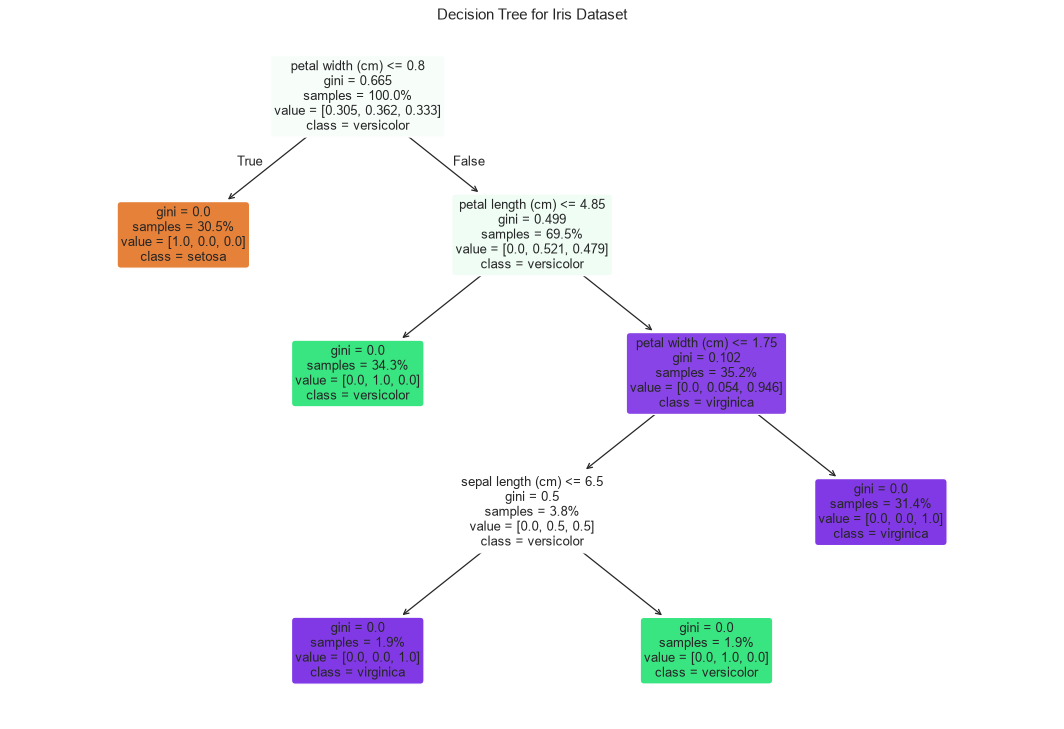

In [4]:
# Plot the figure
plt.figure(figsize=(15, 10))
plot_tree(clf, feature_names=iris.feature_names, class_names=list(iris.target_names),
          filled=True, proportion=True, rounded=True, fontsize=10)
plt.title('Decision Tree for Iris Dataset')
plt.show()

*Tambahan (bukan bagian dari notebook asli):* sel berikut (1) mencetak aturan pohon sebagai teks, (2) menghitung Gini *root* dan penurunan impurity split pertama secara manual untuk memverifikasi rumus di atas, dan (3) membandingkan akurasi latih vs validasi silang untuk berbagai `max_depth` guna melihat *overfitting*.

In [5]:
# (1) Aturan pohon dalam bentuk teks
print(export_text(clf, feature_names=iris.feature_names))

# (2) Verifikasi Gini root dan split pertama secara manual
def gini(labels):
    p = np.bincount(labels, minlength=3) / len(labels)
    return 1 - np.sum(p ** 2)

tree_ = clf.tree_
j, t = tree_.feature[0], tree_.threshold[0]
left = y_train[X_train[:, j] <= t]
right = y_train[X_train[:, j] > t]
g_root, g_left, g_right = gini(y_train), gini(left), gini(right)
gain = g_root - len(left) / len(y_train) * g_left - len(right) / len(y_train) * g_right
print(f'Split root: {iris.feature_names[j]} <= {t:.3f}')
print(f'Gini root manual = {g_root:.4f} | dari sklearn = {tree_.impurity[0]:.4f}')
print(f'Gini kiri = {g_left:.4f} (n={len(left)}), Gini kanan = {g_right:.4f} (n={len(right)})')
print(f'Penurunan impurity split pertama = {gain:.4f}')

# (3) Efek max_depth: akurasi latih vs 5-fold CV (pada data latih)
rows = []
for d in [1, 2, 3, 4, 5, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=2024)
    cv = cross_val_score(m, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=2024))
    m.fit(X_train, y_train)
    rows.append({'max_depth': str(d), 'leaf': m.get_n_leaves(),
                 'akurasi_latih': m.score(X_train, y_train),
                 'akurasi_CV': cv.mean(), 'std_CV': cv.std(),
                 'akurasi_uji': m.score(X_test, y_test)})
display(pd.DataFrame(rows).round(3))

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal length (cm) <= 4.85
|   |   |--- class: 1
|   |--- petal length (cm) >  4.85
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- sepal length (cm) <= 6.50
|   |   |   |   |--- class: 2
|   |   |   |--- sepal length (cm) >  6.50
|   |   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- class: 2

Split root: petal width (cm) <= 0.800
Gini root manual = 0.6650 | dari sklearn = 0.6650
Gini kiri = 0.0000 (n=32), Gini kanan = 0.4992 (n=73)
Penurunan impurity split pertama = 0.3180


,max_depth,leaf,akurasi_latih,akurasi_CV,std_CV,akurasi_uji
0,1,2,0.667,0.648,0.038,0.667
1,2,3,0.981,0.943,0.047,0.889
2,3,4,0.981,0.943,0.047,0.889
3,4,5,1.000,0.962,0.036,0.867
4,5,5,1.000,0.962,0.036,0.867
5,None,5,1.000,0.962,0.036,0.867


**Interpretasi:**

- **Struktur pohon** (lihat plot dan `export_text`): split *root* adalah `petal width <= 0.80`, yang langsung memisahkan seluruh setosa (32 sampel latih, leaf murni). Cabang kanan dipecah dengan `petal length <= 4.85` (→ versicolor); sisanya dipecah lagi dengan `petal width <= 1.75` dan akhirnya `sepal length <= 6.50`. Split terakhir ini hanya untuk segelintir sampel dan merupakan contoh split yang menghafal *noise* data latih.
- **Verifikasi Gini:** Gini root manual **0.6650** persis sama dengan nilai di `clf.tree_.impurity[0]`, mendekati maksimum $1-1/3=0.667$ karena kelas latih hampir seimbang. Setelah split pertama, anak kiri murni (Gini 0) dan anak kanan Gini 0.499 (dua kelas hampir seimbang), sehingga penurunan impurity = $0.665 - \tfrac{73}{105}\cdot0.499 = $ **0.318** — terbesar di antara semua split kandidat, itulah sebabnya split ini dipilih CART.
- **Efek `max_depth`:** kedalaman 1 jelas *underfitting* (akurasi ~0.65–0.67, hanya setosa vs sisanya). Dari kedalaman 2 ke atas akurasi latih naik dari 0.981 ke 1.000 dan akurasi CV naik dari 0.943 ke **0.962** (std ~0.04), lalu tetap sama karena pohon penuh hanya sedalam 4. Menariknya akurasi **uji** justru paling tinggi untuk kedalaman 2–3 (0.889) dibanding 0.867 untuk pohon penuh — tetapi perbedaannya hanya 1 sampel dan berada di dalam simpangan baku CV, contoh betapa berisiknya evaluasi pada data uji 45 sampel.

## 8.2 Random Forest dan Bagging

**Teori:**

**Mengapa ensemble mengurangi varians.** Misalkan kita merata-ratakan $B$ prediktor yang masing-masing memiliki varians $\sigma^2$ dan korelasi berpasangan $\rho$. Varians rata-ratanya adalah

$$
\operatorname{Var}\Big(\frac{1}{B}\sum_{b=1}^{B}\hat f_b(x)\Big) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .
$$

Saat $B\to\infty$ suku kedua hilang, tetapi suku pertama $\rho\sigma^2$ tetap ada. Jadi kunci ensemble yang baik adalah **banyak model** (B besar) yang **tidak saling berkorelasi** (ρ kecil). Bias rata-rata sama dengan bias satu pohon, sehingga yang diturunkan terutama varians — cocok untuk pohon dalam yang bias-nya rendah tetapi variansnya tinggi.

**Bagging (*bootstrap aggregating*, Breiman 1996).** Untuk $b=1,\dots,B$: ambil sampel *bootstrap* (sampling $n$ titik dengan pengembalian) dari data latih, latih satu pohon penuh pada sampel itu, lalu gabungkan prediksi dengan *majority vote* (klasifikasi) atau rata-rata (regresi). scikit-learn's `RandomForestClassifier` sebenarnya merata-ratakan **probabilitas** kelas (*soft voting*). Peluang sebuah titik **tidak** terambil dalam satu bootstrap adalah $(1-1/n)^n \approx e^{-1} \approx 0.368$; titik-titik ini disebut **out-of-bag (OOB)** dan dapat dipakai sebagai himpunan validasi gratis (`oob_score=True`).

**Random forest (Breiman 2001)** = bagging + **pemilihan fitur acak di setiap split**: pada tiap node hanya `max_features` fitur acak yang dipertimbangkan (default klasifikasi: $\sqrt{p}$). Ini memaksa pohon-pohon memakai fitur yang berbeda sehingga korelasi $\rho$ antar pohon turun, dan varians ensemble turun lebih jauh dibanding bagging biasa.

**Hyperparameter penting:** `n_estimators` (lebih banyak hampir tidak pernah merugikan akurasi, hanya biaya komputasi), `max_features` (trade-off korelasi vs kekuatan pohon), `max_depth`/`min_samples_leaf` (kompleksitas tiap pohon), `bootstrap`, `class_weight`, `n_jobs` (paralel karena pohon independen).

**Feature importance (MDI — *mean decrease in impurity*).** Untuk setiap fitur, jumlahkan penurunan impurity tertimbang ($\frac{n_m}{n}\Delta I$) di semua node yang memakai fitur tersebut, rata-ratakan di semua pohon, lalu normalisasi agar totalnya 1. *Pitfall:* MDI dihitung pada data latih dan bias terhadap fitur kontinu/berkardinalitas tinggi; untuk fitur yang saling berkorelasi, kepentingan "dibagi" di antara mereka. *Permutation importance* pada data uji adalah alternatif yang lebih andal.

In [6]:
# Load the dataset (sama seperti 8.1)
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Instantiate the model
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)

# Fit the model to the training data
rf_clf.fit(X_train, y_train)

# Generate predictions
y_pred = rf_clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f'Akurasi uji Random Forest: {accuracy:.4f}')
styled_report(y_test, y_pred, target_names=iris.target_names)

Akurasi uji Random Forest: 0.9111


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.833,0.833,0.833,12
virginica,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


**Interpretasi:**

- Random forest 100 pohon mencapai akurasi uji **0.911** (41 dari 45 benar, 4 salah), lebih baik daripada satu decision tree (0.867). Precision dan recall versicolor naik ke **0.833/0.833**, virginica ke **0.867/0.867**; setosa tetap sempurna.
- Peningkatan ini sesuai teori: merata-ratakan probabilitas dari banyak pohon yang dilatih pada sampel bootstrap dan subset fitur acak menghaluskan batas keputusan di daerah tumpang tindih versicolor/virginica, sehingga mengurangi kesalahan yang berasal dari varians satu pohon. Namun selisih 2 sampel pada data uji kecil belum cukup untuk menyimpulkan keunggulan (lihat sel tambahan di bawah).

Visualisasi *feature importance* untuk melihat fitur mana yang paling berkontribusi pada keputusan:

petal length (cm)   : 0.4489
petal width (cm)    : 0.4360
sepal length (cm)   : 0.0901
sepal width (cm)    : 0.0251


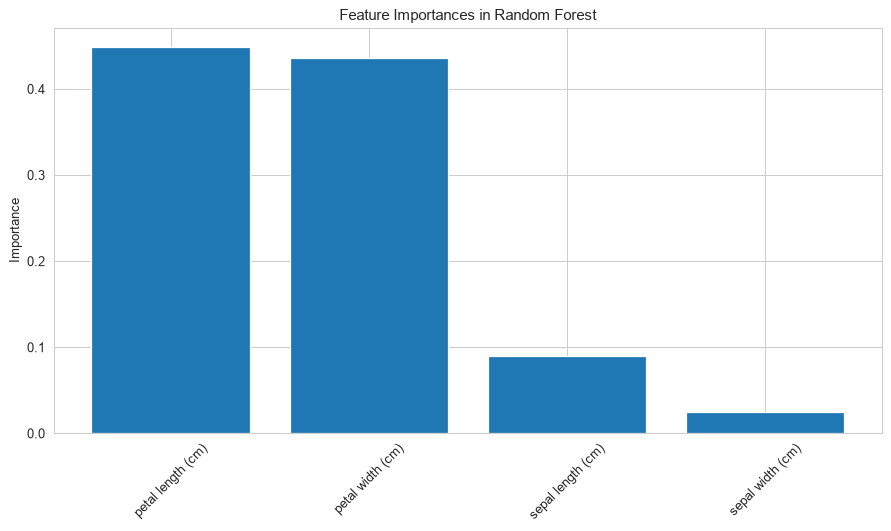

In [7]:
# Calculate feature importance
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

for i in indices:
    print(f'{iris.feature_names[i]:<20s}: {importances[i]:.4f}')

# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.title('Feature Importances in Random Forest')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), [iris.feature_names[i] for i in indices], rotation=45)
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

**Interpretasi:**

- Dua fitur petal mendominasi: **petal length 0.449** dan **petal width 0.436** (total ~89% dari penurunan impurity), sedangkan sepal length 0.090 dan sepal width hanya 0.025. Ini konsisten dengan struktur pohon tunggal di 8.1 yang hanya memakai fitur petal pada split-split utama.
- Berbeda dengan pohon tunggal yang memakai `petal width` di root, random forest membagi kepentingan hampir rata antara petal length dan petal width. Karena setiap split hanya melihat $\sqrt4=2$ fitur acak, kadang petal width tidak tersedia dan petal length (yang berkorelasi sangat tinggi dengannya) menggantikan perannya — kepentingan dua fitur yang berkorelasi "dibagi" di antara keduanya.

*Tambahan (bukan bagian dari notebook asli):* data uji Iris hanya 45 sampel, sehingga satu kesalahan sudah mengubah akurasi ~2.2 poin. Sel berikut membandingkan satu pohon, bagging, dan random forest dengan **10× repeated stratified 5-fold CV** pada seluruh data, serta menampilkan **OOB score** random forest dan *permutation importance* pada data uji.

In [8]:
from sklearn.inspection import permutation_importance

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=2024)
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=2024),
    'Bagging (100 pohon)': BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=2024),
    'Random Forest (100 pohon)': RandomForestClassifier(n_estimators=100, random_state=2024),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=cv, n_jobs=-1)
    rows.append({'model': name, 'akurasi_CV_mean': s.mean(), 'akurasi_CV_std': s.std()})
display(pd.DataFrame(rows).round(4))

# OOB score: validasi gratis dari sampel yang tidak terambil bootstrap
rf_oob = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=2024).fit(X_train, y_train)
print(f'OOB score (data latih): {rf_oob.oob_score_:.4f}')

# Permutation importance pada data uji
pi = permutation_importance(rf_clf, X_test, y_test, n_repeats=30, random_state=2024)
display(pd.DataFrame({'MDI (impurity)': rf_clf.feature_importances_,
                      'permutation_mean': pi.importances_mean,
                      'permutation_std': pi.importances_std},
                     index=iris.feature_names).round(4))

,model,akurasi_CV_mean,akurasi_CV_std
0,Decision Tree,0.9473,0.0341
1,Bagging (100 pohon),0.9520,0.0341
2,Random Forest (100 pohon),0.9493,0.0341


OOB score (data latih): 0.9619


,MDI (impurity),permutation_mean,permutation_std
sepal length (cm),0.0901,-0.0030,0.0160
sepal width (cm),0.0251,-0.0089,0.0147
petal length (cm),0.4489,0.2000,0.0544
petal width (cm),0.4360,0.4519,0.0627


**Interpretasi:**

- **Repeated CV (50 evaluasi):** decision tree **0.947**, bagging **0.952**, random forest **0.949**, ketiganya dengan std **0.034**. Perbedaan antar model (~0.5 poin) jauh lebih kecil daripada simpangan bakunya, jadi pada Iris ketiganya praktis setara. Alasannya: Iris adalah dataset kecil dan mudah, satu pohon pun sudah memiliki varians rendah, sehingga ruang yang bisa diperbaiki oleh ensemble sangat sedikit. Keunggulan RF di 8.2 (0.911 vs 0.867) sebagian besar adalah keberuntungan pembagian data.
- **OOB score 0.962** pada data latih — estimasi generalisasi "gratis" tanpa memisahkan data validasi; nilainya dekat dengan akurasi CV, bukan dengan akurasi latih (1.0).
- **Permutation importance vs MDI:** pada data uji, mengacak `petal width` menurunkan akurasi rata-rata **0.452**, sedangkan mengacak `petal length` hanya **0.200**, dan fitur sepal ~0 (bahkan sedikit negatif, artinya tidak berguna). Jadi meskipun MDI menilai petal length ≈ petal width, model sebenarnya paling bergantung pada petal width untuk prediksi data baru. Ini menggambarkan *pitfall* MDI: dihitung dari data latih dan membagi kepentingan antar fitur berkorelasi.

## 8.3 Gradient Boosting Machines (GBM)

**Teori:**

**Ide boosting.** Berbeda dengan bagging yang membangun pohon secara **paralel dan independen**, boosting membangun model **secara berurutan**: setiap model baru berfokus memperbaiki kesalahan ensemble sebelumnya. Model dasarnya adalah *weak learner* — biasanya pohon dangkal (default `max_depth=3`) yang bias-nya tinggi tetapi variansnya rendah. Boosting terutama **mengurangi bias**.

**Model aditif bertahap.** GBM membangun

$$
F_M(x) = F_0(x) + \sum_{m=1}^{M} \nu\, h_m(x),
$$

dengan $F_0$ tebakan awal (mis. log-odds prior kelas), $h_m$ pohon regresi ke-$m$, dan $\nu$ = `learning_rate` (*shrinkage*).

**Gradient descent di ruang fungsi (Friedman 2001).** Untuk loss $L(y, F)$ yang terdiferensialkan, pada iterasi $m$:

1. Hitung **pseudo-residual** (negatif gradien loss terhadap prediksi saat ini):
$$ r_{im} = -\left[\frac{\partial L(y_i, F(x_i))}{\partial F(x_i)}\right]_{F=F_{m-1}} .$$
2. Latih pohon regresi $h_m$ untuk memprediksi $r_{im}$ dari $x_i$.
3. Hitung nilai optimal di setiap leaf (satu langkah Newton–Raphson untuk log-loss), lalu perbarui $F_m = F_{m-1} + \nu h_m$.

Untuk loss kuadrat $L=\tfrac12(y-F)^2$, pseudo-residual tepat sama dengan residual biasa $y-F$ — inilah intuisi "setiap pohon memprediksi error pohon sebelumnya". Untuk klasifikasi $K$ kelas dengan log-loss (*multinomial deviance*), scikit-learn melatih **$K$ pohon per iterasi** (satu untuk setiap skor kelas, lalu softmax), sehingga 1000 iterasi pada Iris = 3000 pohon.

**Hyperparameter dan trade-off:**
- `n_estimators` ($M$) dan `learning_rate` ($\nu$) saling terkait: $\nu$ kecil memerlukan $M$ lebih besar tetapi biasanya generalisasinya lebih baik. Berbeda dengan random forest, **$M$ terlalu besar dapat overfitting** karena model terus mengejar residual data latih.
- `max_depth` (kedalaman interaksi; 3–8 umum), `subsample` < 1 (*stochastic gradient boosting*, menambah keacakan dan regularisasi), `min_samples_leaf`, `max_features`.
- *Early stopping* (`n_iter_no_change`, `validation_fraction`) menghentikan pelatihan saat skor validasi tidak membaik.

**Pitfall:** pelatihan sekuensial tidak dapat diparalelkan antar pohon dan lebih lambat dari random forest; GBM lebih sensitif terhadap *hyperparameter* dan *noise* label. Untuk data besar, gunakan `HistGradientBoostingClassifier` (berbasis histogram, jauh lebih cepat, mendukung nilai hilang) atau pustaka seperti XGBoost/LightGBM.

In [9]:
# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Instantiate the model (1000 iterasi, learning rate 0.2 — sesuai buku)
gbm_clf = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, random_state=2024)

# Fit the model to the training data
gbm_clf.fit(X_train, y_train)

# Generate predictions
y_pred = gbm_clf.predict(X_test)
print(f'Akurasi uji GBM  : {accuracy_score(y_test, y_pred):.4f}')
print(f'Akurasi latih GBM: {gbm_clf.score(X_train, y_train):.4f}')
print('Jumlah pohon total:', gbm_clf.estimators_.size, '(iterasi x kelas =', gbm_clf.estimators_.shape, ')')

# Evaluate the model
styled_report(y_test, y_pred, target_names=iris.target_names)

Akurasi uji GBM  : 0.8667
Akurasi latih GBM: 1.0000
Jumlah pohon total: 3000 (iterasi x kelas = (1000, 3) )


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.714,0.833,0.769,12
virginica,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Interpretasi:**

- GBM dengan 1000 iterasi dan `learning_rate=0.2` menghasilkan akurasi latih **1.000** dan akurasi uji **0.867** — laporan klasifikasinya identik dengan decision tree tunggal di 8.1 (6 kesalahan yang sama pada versicolor/virginica), dan sedikit di bawah random forest (0.911).
- Karena Iris memiliki 3 kelas, setiap iterasi melatih 3 pohon regresi (satu per skor kelas), sehingga model berisi **3000 pohon** (`estimators_.shape = (1000, 3)`). Untuk dataset 105 sampel ini jelas berlebihan: setelah residual latih hampir nol, pohon-pohon berikutnya tidak menambah informasi (lihat sel berikut).

*Tambahan (bukan bagian dari notebook asli):* `staged_predict` memungkinkan kita melihat akurasi ensemble setelah setiap iterasi tanpa melatih ulang. Kita plot *training loss* (`train_score_`) dan akurasi uji per iterasi untuk memperlihatkan bagaimana GBM "terus memperbaiki residual" pada data latih, dan berapa iterasi yang sebenarnya dibutuhkan.

Training loss pada iterasi 1, 10, 50, 1000: [7.43077e-01 5.71720e-02 1.00000e-06 0.00000e+00]
Akurasi uji pada iterasi 1, 10, 50, 100, 1000: [0.8667 0.8667 0.8667 0.8667 0.8667]
Iterasi pertama dengan akurasi uji maksimum: 15 (akurasi 0.8889)


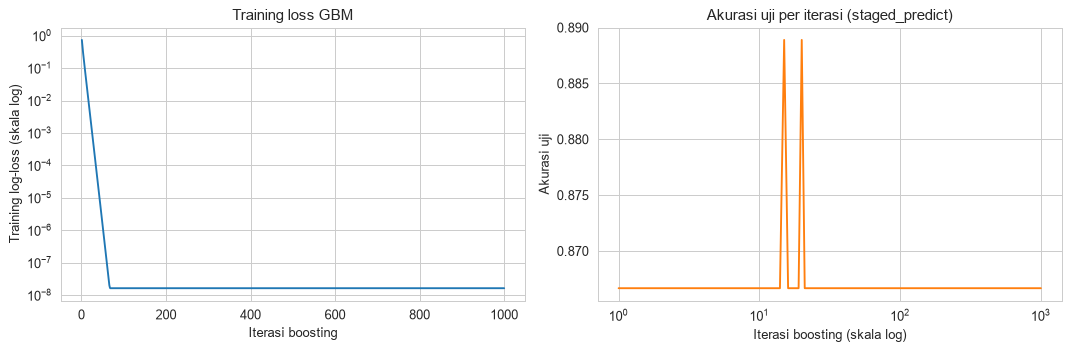

In [10]:
staged_acc = np.array([accuracy_score(y_test, p) for p in gbm_clf.staged_predict(X_test)])
iters = np.arange(1, len(staged_acc) + 1)

print('Training loss pada iterasi 1, 10, 50, 1000:',
      np.round(gbm_clf.train_score_[[0, 9, 49, 999]], 6))
print('Akurasi uji pada iterasi 1, 10, 50, 100, 1000:',
      np.round(staged_acc[[0, 9, 49, 99, 999]], 4))
print('Iterasi pertama dengan akurasi uji maksimum:', iters[staged_acc.argmax()],
      f'(akurasi {staged_acc.max():.4f})')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(iters, gbm_clf.train_score_)
ax[0].set_yscale('log')
ax[0].set_xlabel('Iterasi boosting')
ax[0].set_ylabel('Training log-loss (skala log)')
ax[0].set_title('Training loss GBM')
ax[1].plot(iters, staged_acc, color='tab:orange')
ax[1].set_xscale('log')
ax[1].set_xlabel('Iterasi boosting (skala log)')
ax[1].set_ylabel('Akurasi uji')
ax[1].set_title('Akurasi uji per iterasi (staged_predict)')
plt.tight_layout()
plt.show()

**Interpretasi:**

- **Training loss** turun sangat cepat: log-loss **0.743** setelah 1 iterasi, **0.057** setelah 10 iterasi, ~$10^{-6}$ setelah 50 iterasi, dan **0** (sampai presisi mesin) pada iterasi 1000. Ini mencerminkan cara kerja GBM: setiap pohon mengurangi residual (gradien) yang tersisa sampai data latih dihafal sepenuhnya.
- **Akurasi uji** sudah **0.867** sejak iterasi pertama, hanya sempat naik ke **0.889** pada iterasi 15 dan 20, lalu kembali ke 0.867 dan tidak berubah sampai iterasi 1000. Jadi ~98% iterasi tidak menambah akurasi uji sama sekali — hanya menambah waktu dan membuat probabilitas prediksi semakin ekstrem (*overconfident*, loss latih → 0). Dalam praktik, *early stopping* (`n_iter_no_change`) atau `learning_rate` lebih kecil dengan `n_estimators` yang dituning (8.4) jauh lebih efisien.

## 8.4 Hyperparameter Tuning untuk Pohon dan Ensemble

**Teori:**

**Parameter vs hyperparameter.** Parameter (split dan nilai leaf) dipelajari dari data oleh `fit()`; *hyperparameter* (mis. `max_depth`, `n_estimators`, `learning_rate`) ditetapkan sebelum pelatihan dan mengatur kapasitas model — yaitu posisi model pada *bias–variance trade-off*.

**Grid search + k-fold cross-validation.** `GridSearchCV` mencoba **semua kombinasi** pada grid (di sini $3\times3\times3=27$ kombinasi). Untuk setiap kombinasi, data latih dibagi menjadi $k=5$ fold; model dilatih pada 4 fold dan dievaluasi pada fold sisanya, bergiliran, lalu skornya dirata-ratakan:

$$
\text{CV}(\theta) = \frac{1}{k}\sum_{i=1}^{k} \text{Acc}\big(\hat f_{\theta}^{(-i)},\ \text{fold}_i\big).
$$

Kombinasi dengan $\text{CV}(\theta)$ tertinggi dipilih, lalu (karena `refit=True`) model dilatih ulang pada seluruh data latih dan tersedia sebagai `best_estimator_`. Total pelatihan = $27\times5+1=136$ model. Untuk klasifikasi, scikit-learn otomatis memakai `StratifiedKFold` sehingga proporsi kelas tiap fold terjaga.

**Hyperparameter khas model pohon:**
- *Decision tree:* `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_leaf_nodes`, `ccp_alpha`, `criterion`.
- *Random forest:* `n_estimators`, `max_features`, `max_depth`, `min_samples_leaf`, `bootstrap`.
- *GBM:* `n_estimators` × `learning_rate` (harus dituning bersama), `max_depth`, `subsample`, `min_samples_leaf`.

**Pitfall:**
- Grid search mahal (tumbuh eksponensial dengan jumlah hyperparameter); `RandomizedSearchCV` atau `HalvingGridSearchCV` lebih efisien untuk ruang besar.
- Pada dataset kecil seperti Iris, banyak kombinasi mencapai skor CV **seri**; `best_params_` lalu sekadar kombinasi pertama yang mencapai skor maksimum (urutan grid), bukan bukti bahwa kombinasi itu benar-benar unggul.
- Skor CV terbaik bersifat **optimistis** (dipilih dari banyak kandidat); evaluasi akhir harus pada data uji yang tidak pernah dipakai saat tuning (atau *nested CV*).
- Heatmap yang mem-*pivot* dua hyperparameter secara otomatis **merata-ratakan** hyperparameter ketiga (di sini `learning_rate`).

In [11]:
# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

# Set up GridSearchCV()
grid_search = GridSearchCV(GradientBoostingClassifier(random_state=2024),
                           param_grid,
                           cv=5,
                           scoring='accuracy',
                           n_jobs=-1)

# Fit GridSearchCV() to training data
grid_search.fit(X_train, y_train)

# Identify the best parameters
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Best CV accuracy: {grid_search.best_score_:.4f}')

# Berapa banyak kombinasi yang seri dengan skor terbaik?
res = pd.DataFrame(grid_search.cv_results_)
n_tie = np.isclose(res['mean_test_score'], grid_search.best_score_).sum()
print(f'Jumlah kombinasi dengan skor CV = skor terbaik: {n_tie} dari {len(res)}')

# Evaluate the best model
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print(f'Akurasi uji best model: {accuracy_score(y_test, y_pred):.4f}')

# Generate classification report
styled_report(y_test, y_pred, target_names=iris.target_names)

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
Best CV accuracy: 0.9810
Jumlah kombinasi dengan skor CV = skor terbaik: 20 dari 27
Akurasi uji best model: 0.8667


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.714,0.833,0.769,12
virginica,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Interpretasi:**

- Grid search memilih `{'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}` dengan akurasi CV terbaik **0.981** (rata-rata dari 5 fold berisi 21 sampel; setara hanya 2 kesalahan dari 105 prediksi validasi).
- Namun **20 dari 27** kombinasi mencapai skor CV yang sama persis (0.981). `best_params_` hanyalah kombinasi pertama dengan peringkat 1 menurut urutan grid (`learning_rate` terkecil, lalu `max_depth`, lalu `n_estimators`), bukan pemenang yang sebenarnya. Pada dataset sekecil ini, grid search tidak mampu membedakan kandidat.
- Akurasi uji model terbaik **0.867** — sama dengan GBM default dan decision tree (6 kesalahan yang sama), dan lebih rendah dari skor CV 0.981. Selisih ini menunjukkan bahwa skor CV terbaik bersifat **optimistis** (dipilih dari banyak kandidat yang seri) dan bahwa pembagian uji ini memuat beberapa bunga versicolor/virginica yang memang sulit dipisahkan oleh model berbasis pohon apa pun.

Heatmap rata-rata skor CV untuk kombinasi `max_depth` × `n_estimators` (seperti di buku), ditambah heatmap `learning_rate` × `n_estimators` (*tambahan*) karena pivot pertama merata-ratakan `learning_rate`:

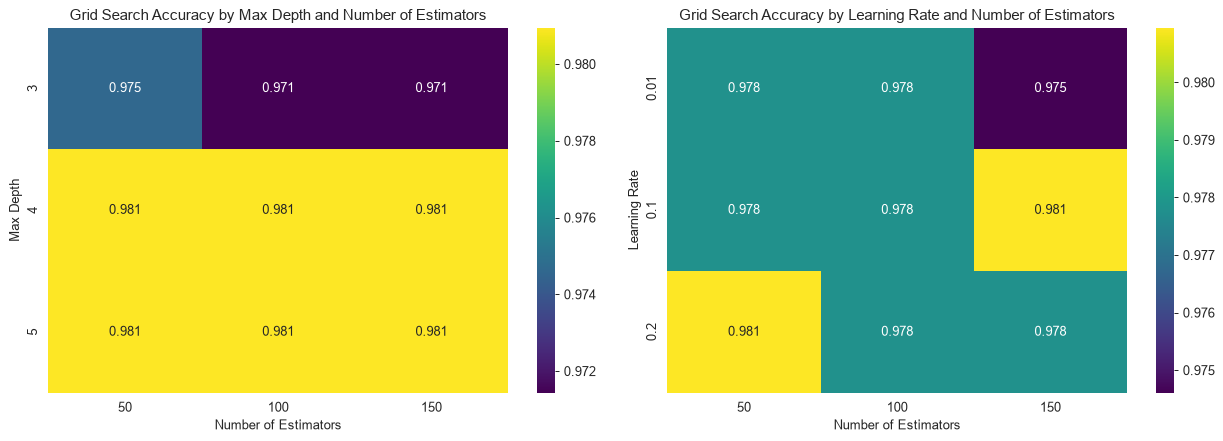

In [12]:
# Create a pivot table
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(values='mean_test_score',
                                  index='param_max_depth',
                                  columns='param_n_estimators')
# Tambahan: pivot learning_rate x n_estimators
pivot_lr = results.pivot_table(values='mean_test_score',
                               index='param_learning_rate',
                               columns='param_n_estimators')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='viridis', ax=ax[0])
ax[0].set_title('Grid Search Accuracy by Max Depth and Number of Estimators')
ax[0].set_xlabel('Number of Estimators')
ax[0].set_ylabel('Max Depth')
sns.heatmap(pivot_lr, annot=True, fmt='.3f', cmap='viridis', ax=ax[1])
ax[1].set_title('Grid Search Accuracy by Learning Rate and Number of Estimators')
ax[1].set_xlabel('Number of Estimators')
ax[1].set_ylabel('Learning Rate')
plt.tight_layout()
plt.show()

**Interpretasi:**

- **Heatmap kiri (`max_depth` × `n_estimators`, dirata-rata atas `learning_rate`):** `max_depth=3` sedikit lebih buruk (**0.971–0.975**), sedangkan `max_depth` 4 dan 5 menghasilkan **0.981** di semua jumlah estimator. Variasi seluruh grid hanya ~1 poin (= kira-kira 1 sampel validasi), sehingga permukaan skor nyaris datar.
- **Heatmap kanan (`learning_rate` × `n_estimators`):** semua sel berada di rentang **0.975–0.981** tanpa pola yang jelas. Untuk Iris, kombinasi apa pun yang cukup kuat sudah mendekati batas akurasi yang mungkin; tuning baru berarti pada data yang lebih besar dan lebih sulit.
- Pelajaran praktis: selalu periksa *seberapa datar* permukaan skor CV dan berapa banyak kandidat yang seri sebelum mempercayai `best_params_`. Bila banyak yang seri, pilihlah model paling sederhana/cepat (mis. `n_estimators` kecil).

## 8.5 Membandingkan Metode Ensemble (Bagging, Boosting, Stacking)

**Teori:**

Tiga keluarga ensemble utama menyerang komponen galat yang berbeda dari dekomposisi $\text{Error} = \text{Bias}^2 + \text{Variance} + \text{Noise}$:

| Metode | Cara membangun | Base learner tipikal | Terutama mengurangi | Paralel? |
|---|---|---|---|---|
| **Bagging / Random Forest** | Model independen pada sampel bootstrap, hasil dirata-ratakan/vote | Pohon dalam (bias rendah, varians tinggi) | Varians | Ya |
| **Boosting (GBM, AdaBoost)** | Model berurutan, tiap model memperbaiki kesalahan sebelumnya | Pohon dangkal (bias tinggi, varians rendah) | Bias (juga varians lewat shrinkage) | Tidak |
| **Stacking** | Beberapa model berbeda (level-0), prediksinya menjadi fitur untuk *meta-model* (level-1) | Model heterogen | Keduanya, dengan memanfaatkan kekuatan tiap model | Level-0 ya |

**Stacking (*stacked generalization*, Wolpert 1992).** Jika meta-model dilatih pada prediksi base model terhadap data yang **sama** dengan data latih base model, meta-model akan terlalu percaya pada base model yang overfitting. Karena itu `StackingClassifier` memakai **prediksi out-of-fold** dari *cross-validation* internal (`cv=5`): setiap sampel latih diprediksi oleh base model yang tidak melihat sampel itu. Fitur meta-model untuk klasifikasi adalah probabilitas kelas (`predict_proba`) dari setiap base model, sehingga di sini meta-model `LogisticRegression` menerima $2\times3=6$ fitur. Setelah itu base model dilatih ulang pada seluruh data latih untuk dipakai saat prediksi.

**Kapan stacking membantu?** Bila base model **beragam** dan membuat kesalahan yang berbeda (korelasi kesalahan rendah). Bila semua base model sudah hampir sempurna atau membuat kesalahan yang sama, stacking tidak bisa menambah apa-apa, sementara biayanya jauh lebih besar ($k+1$ kali pelatihan setiap base model).

**Pitfall dalam membandingkan model:** pada data uji kecil (45 sampel), perbedaan satu-dua prediksi tidak bermakna secara statistik. Perbandingan yang adil sebaiknya memakai *repeated cross-validation* dan melaporkan rata-rata ± simpangan baku.

In [13]:
# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Instantiate models
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, random_state=2024)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('gb', gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5
)
# Fit the models
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

# Evaluate the models
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

# Print the accuracy scores
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')
print(f'Stacking Accuracy: {stacking_accuracy:.2f}')

# Detail tambahan: jumlah salah prediksi dan apakah kesalahan model sama
for name, p in [('RF', rf_pred), ('GB', gb_pred), ('Stacking', stacking_pred)]:
    print(f'{name:<9s} salah pada indeks uji: {np.where(p != y_test)[0].tolist()}')
print('Koefisien meta-model (kelas x fitur meta):')
print(np.round(stacking_clf.final_estimator_.coef_, 2))

Random Forest Accuracy: 0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy: 0.87
RF        salah pada indeks uji: [3, 10, 17, 35]
GB        salah pada indeks uji: [3, 10, 17, 26, 35, 38]
Stacking  salah pada indeks uji: [3, 10, 17, 26, 35, 38]
Koefisien meta-model (kelas x fitur meta):
[[ 1.36 -0.66 -0.7   1.38 -0.64 -0.74]
 [-0.72  1.09 -0.37 -0.74  1.25 -0.51]
 [-0.64 -0.43  1.07 -0.64 -0.6   1.25]]


**Interpretasi:**

- Pada pembagian uji yang sama, **Random Forest 0.91** (4 kesalahan), sedangkan **Gradient Boosting 0.87** dan **Stacking 0.87** (masing-masing 6 kesalahan). Bar plot di bawah memperlihatkan perbedaan ini.
- Indeks kesalahan menjelaskan mengapa stacking tidak membantu: kesalahan RF `[3, 10, 17, 35]` adalah **subset** dari kesalahan GB `[3, 10, 17, 26, 35, 38]`, dan kesalahan stacking **identik** dengan GB. Kedua base model membuat kesalahan yang hampir sama (keragaman rendah), sehingga meta-model tidak punya informasi tambahan untuk dikoreksi.
- Koefisien meta-model `LogisticRegression` memperlihatkan bobot yang sedikit lebih besar untuk probabilitas GB (kolom 4–6: 1.38, 1.25, 1.25 pada kelas masing-masing) dibanding RF (kolom 1–3: 1.36, 1.09, 1.07). Pada prediksi *out-of-fold* GB tampak sedikit lebih andal, sehingga stacking "mengikuti" GB — termasuk pada dua sampel (26 dan 38) yang sebenarnya benar diprediksi RF.

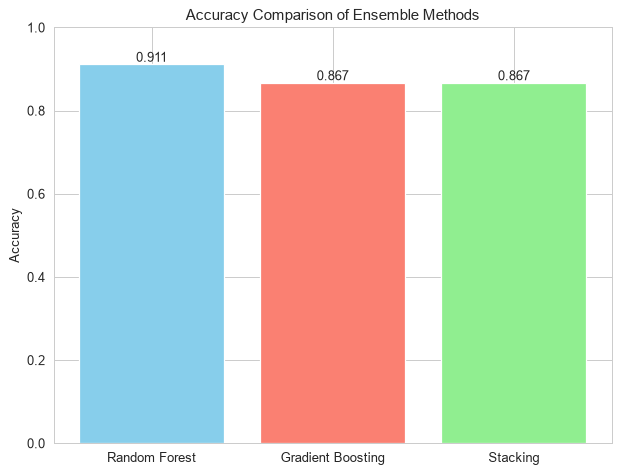

In [14]:
# Create a bar plot
methods = ['Random Forest', 'Gradient Boosting', 'Stacking']
accuracies = [rf_accuracy, gb_accuracy, stacking_accuracy]

# Plot the bar plot
plt.figure(figsize=(8, 6))
bars = plt.bar(methods, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
plt.bar_label(bars, fmt='%.3f')
plt.title('Accuracy Comparison of Ensemble Methods')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

*Tambahan (bukan bagian dari notebook asli):* perbandingan yang lebih adil dengan **5-fold CV diulang 3 kali** pada seluruh 150 sampel, ditambah dua ensemble lain dari scikit-learn: `BaggingClassifier` (bagging murni tanpa pemilihan fitur acak) dan `AdaBoostClassifier` (boosting dengan pembobotan ulang sampel).

,model,akurasi_CV_mean,akurasi_CV_std
0,Gradient Boosting,0.9600,0.0278
1,Stacking (RF+GB -> LR),0.9578,0.0285
2,Bagging,0.9556,0.0314
3,Decision Tree,0.9556,0.0199
4,Random Forest,0.9533,0.0361
5,AdaBoost,0.9378,0.0319


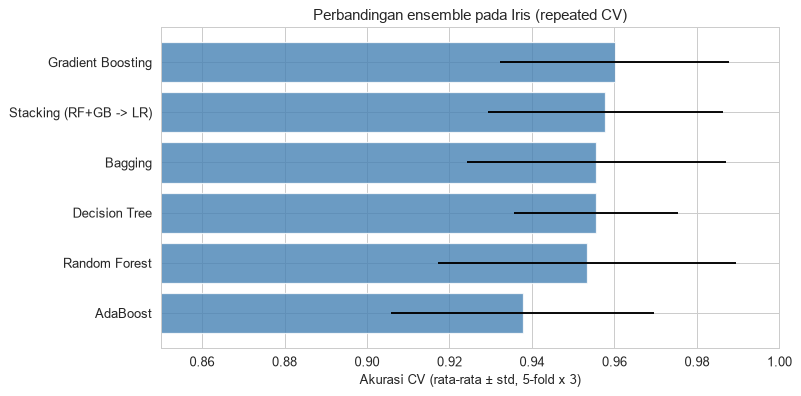

In [15]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
candidates = {
    'Decision Tree': DecisionTreeClassifier(random_state=2024),
    'Bagging': BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=2024),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=2024),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=2024),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=2024),
    'Stacking (RF+GB -> LR)': StackingClassifier(
        estimators=[('rf', RandomForestClassifier(n_estimators=100, random_state=2024)),
                    ('gb', GradientBoostingClassifier(n_estimators=100, random_state=2024))],
        final_estimator=LogisticRegression(), cv=5),
}
rows = []
for name, m in candidates.items():
    s = cross_val_score(m, X, y, cv=cv, n_jobs=-1)
    rows.append({'model': name, 'akurasi_CV_mean': s.mean(), 'akurasi_CV_std': s.std()})
cv_df = pd.DataFrame(rows).sort_values('akurasi_CV_mean', ascending=False).reset_index(drop=True)
display(cv_df.round(4))

plt.figure(figsize=(9, 4.5))
plt.barh(cv_df['model'], cv_df['akurasi_CV_mean'], xerr=cv_df['akurasi_CV_std'], color='steelblue', alpha=0.8)
plt.xlim(0.85, 1.0)
plt.xlabel('Akurasi CV (rata-rata ± std, 5-fold x 3)')
plt.title('Perbandingan ensemble pada Iris (repeated CV)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretasi:**

- Dengan 5-fold CV diulang 3 kali pada seluruh data, peringkatnya **berbalik** dibanding satu pembagian uji: **Gradient Boosting 0.960**, Stacking 0.958, Bagging 0.956, Decision Tree 0.956, Random Forest 0.953, dan **AdaBoost 0.938** terendah. Simpangan baku berkisar **0.020–0.036**, sehingga lima model teratas berbeda kurang dari setengah simpangan baku — secara statistik setara.
- AdaBoost (default: *decision stump* kedalaman 1) sedikit tertinggal karena stump hanya dapat memakai satu fitur per pohon dan boosting dengan pembobotan ulang sampel peka terhadap titik versicolor/virginica yang tumpang tindih.
- Kesimpulan: (1) keunggulan RF 0.91 vs 0.87 di sel sebelumnya hanyalah efek pembagian data; (2) pada dataset kecil dan mudah seperti Iris, ensemble tidak memberi keuntungan berarti dibanding satu pohon, sementara biaya stacking paling besar; (3) perbandingan model harus memakai repeated CV, bukan satu *train/test split*.

## Latihan

Bagian ini mereproduksi tiga latihan di akhir chapter beserta solusinya (dari notebook *Exercise Solutions*). Setiap latihan memakai dataset bawaan scikit-learn yang berbeda dari Iris:

- **Wine** (178 sampel, 13 fitur kimia, 3 kultivar) — decision tree dasar.
- **Breast cancer Wisconsin** (569 sampel, 30 fitur, biner: 0 = *malignant*, 1 = *benign*) — tuning random forest.
- **Digits** (1797 gambar 8×8 piksel angka tulisan tangan, 64 fitur, 10 kelas) — GBM vs random forest.

### Exercise 1: Building and Evaluating a Decision Tree Classifier

In [16]:
# Load the dataset
wine = load_wine()
X = wine.data
y = wine.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train the classifier
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Evaluate performance
print(classification_report(y_test, y_pred, target_names=wine.target_names))
print('Kedalaman:', clf.get_depth(), '| leaf:', clf.get_n_leaves(),
      '| akurasi latih:', clf.score(X_train, y_train))
print('Confusion matrix (baris = aktual, kolom = prediksi):')
print(confusion_matrix(y_test, y_pred))
top = np.argsort(clf.feature_importances_)[::-1][:3]
print('3 fitur terpenting:', [(wine.feature_names[i], round(float(clf.feature_importances_[i]), 3)) for i in top])

              precision    recall  f1-score   support

     class_0       1.00      0.78      0.88        18
     class_1       0.79      0.95      0.86        20
     class_2       0.94      0.94      0.94        16

    accuracy                           0.89        54
   macro avg       0.91      0.89      0.89        54
weighted avg       0.90      0.89      0.89        54

Kedalaman: 4 | leaf: 7 | akurasi latih: 1.0
Confusion matrix (baris = aktual, kolom = prediksi):
[[14  4  0]
 [ 0 19  1]
 [ 0  1 15]]
3 fitur terpenting: [('flavanoids', 0.398), ('color_intensity', 0.39), ('proline', 0.142)]


**Interpretasi:**

- Decision tree pada dataset **wine** mencapai akurasi uji **0.89** (48 dari 54 benar) dengan akurasi latih 1.0, kedalaman 4, dan 7 leaf — lagi-lagi pohon penuh yang menghafal data latih.
- *Confusion matrix* memperlihatkan sumber kesalahan utama: **4 dari 18** wine `class_0` diprediksi sebagai `class_1` (recall class_0 hanya **0.78**, meskipun precision-nya 1.00). `class_1` (recall 0.95) dan `class_2` (F1 0.94) hampir sempurna; hanya ada 1 pertukaran di antara keduanya.
- Fitur terpenting adalah **flavanoids (0.398)**, **color_intensity (0.390)**, dan **proline (0.142)** — tiga fitur ini menyumbang ~93% penurunan impurity, sehingga 10 fitur lain hampir tidak dipakai. Karena pohon tidak memerlukan *scaling*, perbedaan skala besar antar fitur wine (mis. proline ratusan–ribuan vs hue ~1) tidak menjadi masalah.

### Exercise 2: Hyperparameter Tuning with Random Forests

In [17]:
# Load the dataset
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define hyperparameter grid and perform grid search
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2']
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid, cv=5,
                           error_score='raise', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Evaluate the best model
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Best CV accuracy: {grid_search.best_score_:.4f}')
print(f'Accuracy: {accuracy:.2f}  (tepatnya {accuracy:.4f})')
print('Confusion matrix (0 = malignant, 1 = benign):')
print(confusion_matrix(y_test, y_pred))

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}
Best CV accuracy: 0.9549
Accuracy: 0.95  (tepatnya 0.9532)
Confusion matrix (0 = malignant, 1 = benign):
[[ 62   5]
 [  3 101]]


**Interpretasi:**

- Grid search $3\times3\times2=18$ kombinasi memilih `{'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}` dengan akurasi CV **0.955**; akurasi uji model terbaik **0.95** (tepatnya 0.9532, 163 dari 171 benar) — sangat dekat dengan skor CV, menandakan estimasi CV cukup andal untuk dataset 569 sampel ini.
- Pohon dibatasi `max_depth=5` (bukan 7) dan `max_features='sqrt'` (≈5 dari 30 fitur per split) terpilih: pohon yang lebih dangkal dan lebih beragam memberi generalisasi terbaik di grid ini.
- *Confusion matrix*: **5 tumor malignant diprediksi benign** (*false negative*, recall malignant 62/67 ≈ 0.925) dan 3 tumor benign diprediksi malignant. Dalam konteks medis, *false negative* jauh lebih berbahaya; akurasi saja tidak cukup — sebaiknya tuning memakai metrik seperti recall kelas malignant atau menyesuaikan *threshold* probabilitas / `class_weight`.

### Exercise 3: Comparing Gradient Boosting and Random Forest

In [18]:
# Load the dataset
digits = load_digits()
X = digits.data
y = digits.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train models
import time
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=2024)
t0 = time.perf_counter(); rf_clf.fit(X_train, y_train); t_rf = time.perf_counter() - t0
t0 = time.perf_counter(); gb_clf.fit(X_train, y_train); t_gb = time.perf_counter() - t0

# Make predictions and evaluate
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
print(f'Random Forest Accuracy: {rf_accuracy:.2f}  (tepatnya {rf_accuracy:.4f}, waktu latih {t_rf:.1f} s)')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}  (tepatnya {gb_accuracy:.4f}, waktu latih {t_gb:.1f} s)')
print('Jumlah pohon: RF =', len(rf_clf.estimators_), '| GB =', gb_clf.estimators_.size,
      '(100 iterasi x 10 kelas)')

Random Forest Accuracy: 0.97  (tepatnya 0.9685, waktu latih 0.6 s)
Gradient Boosting Accuracy: 0.96  (tepatnya 0.9648, waktu latih 9.5 s)
Jumlah pohon: RF = 100 | GB = 1000 (100 iterasi x 10 kelas)


**Interpretasi:**

- Pada **digits** (540 sampel uji, 10 kelas), Random Forest mencapai **0.97** (0.9685, 523 benar) dan Gradient Boosting **0.96** (0.9648, 521 benar). Selisihnya hanya 2 gambar, jadi keduanya praktis setara dalam akurasi.
- Perbedaan besar ada pada **biaya**: GB melatih **1000 pohon** (100 iterasi × 10 kelas) secara berurutan dan membutuhkan waktu belasan kali lebih lama (~9.5 s vs ~0.5–0.6 s pada eksekusi ini; waktu dapat sedikit berbeda antar run), sedangkan RF hanya 100 pohon yang independen. Untuk data berdimensi tinggi dan banyak kelas, RF adalah *baseline* yang sangat kuat dan murah; GB biasanya baru unggul setelah tuning (`learning_rate`, `max_depth`, `subsample`) atau dengan implementasi histogram (`HistGradientBoostingClassifier`).

## Ringkasan Chapter 8

1. **Decision tree** mempartisi ruang fitur secara rekursif dan *greedy* (algoritma CART) dengan memilih split yang memaksimalkan penurunan impurity (Gini $1-\sum_k p_k^2$ atau entropy). Pada Iris, split root `petal width <= 0.80` memisahkan semua setosa dan menurunkan Gini dari 0.665 sebesar 0.318. Pohon penuh mencapai akurasi latih 1.0 tetapi uji 0.867 — mudah ditafsirkan, tidak butuh *scaling*, namun rawan *overfitting* dan berarians tinggi; kendalikan dengan `max_depth`, `min_samples_leaf`, atau `ccp_alpha`.
2. **Bagging dan random forest** merata-ratakan banyak pohon yang dilatih pada sampel bootstrap; random forest menambahkan pemilihan fitur acak di setiap split untuk menurunkan korelasi antar pohon, sehingga varians $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$ mengecil. RF memberi akurasi uji 0.911 dan OOB score 0.962. *Feature importance* MDI menilai petal length ≈ petal width (~0.44 masing-masing), sedangkan *permutation importance* menunjukkan model terutama bergantung pada petal width.
3. **Gradient boosting** membangun model aditif $F_M = F_0 + \nu\sum_m h_m$ secara berurutan; setiap pohon dangkal di-*fit* ke pseudo-residual (negatif gradien loss), dengan $K$ pohon per iterasi untuk $K$ kelas. Boosting terutama mengurangi bias, tetapi `n_estimators` yang berlebihan hanya menghafal data latih: dengan 1000 iterasi loss latih → 0 sementara akurasi uji sudah stagnan sejak iterasi pertama.
4. **Hyperparameter tuning** dengan `GridSearchCV` + 5-fold CV memilih kombinasi dengan skor CV tertinggi lalu melatih ulang (`refit`). Pada Iris 20 dari 27 kombinasi GBM seri di 0.981 dan heatmap hampir datar, sehingga `best_params_` tidak bermakna; skor CV terbaik juga optimistis dibanding akurasi uji (0.867). Pada *breast cancer*, tuning RF menghasilkan CV 0.955 dan uji 0.953 yang konsisten.
5. **Bagging mengurangi varians, boosting mengurangi bias, stacking menggabungkan model berbeda lewat meta-model** yang dilatih pada prediksi *out-of-fold*. Stacking RF+GB tidak membantu di Iris karena kesalahan kedua base model hampir identik (keragaman rendah). Dengan repeated CV, semua ensemble (0.953–0.960) setara dengan satu pohon (0.956), dan peringkatnya berbalik dibanding satu pembagian uji — perbandingan model harus memakai CV berulang.
6. **Latihan** menegaskan pola yang sama: pohon tunggal pada wine (0.89) bertumpu pada tiga fitur; RF yang dituning pada breast cancer (0.95) masih menghasilkan 5 *false negative* sehingga metrik selain akurasi perlu diperhatikan; pada digits RF (0.97) dan GB (0.96) setara, tetapi GB jauh lebih mahal (1000 pohon sekuensial).

**Pesan utama:** mulailah dengan decision tree untuk interpretasi, gunakan random forest sebagai *baseline* ensemble yang kuat, murah, dan minim tuning, lalu coba gradient boosting (dengan `learning_rate`, `n_estimators`, dan *early stopping* yang dituning) bila dibutuhkan akurasi lebih tinggi. Evaluasi selalu dengan *cross-validation* berulang, waspadai skor yang seri atau optimistis, dan gunakan stacking hanya bila base model benar-benar beragam.